In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data/placements.csv")

In [3]:
print(df.shape)
df.head()

(1000, 3)


,cgpa,resumeScore,placed
0,8.87,34.3,0
1,7.19,62.1,0
2,9.29,39.0,1
3,8.49,40.7,0
4,5.47,74.3,0


<Axes: xlabel='cgpa', ylabel='resumeScore'>

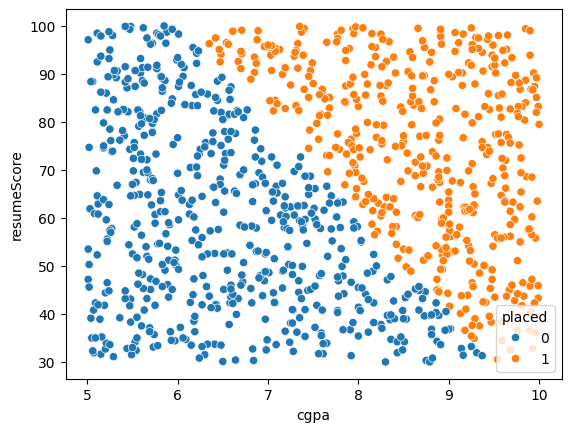

In [4]:
sns.scatterplot(data=df, x='cgpa', y='resumeScore', hue='placed')

In [5]:
X = df.iloc[:,0:2]
y = df.iloc[:, -1]

In [6]:
from sklearn.linear_model import Perceptron
p = Perceptron()

In [7]:
p.fit(X, y)

,penalty,None
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,eta0,1.0
,n_jobs,None
,random_state,0


In [8]:
p.coef_

array([[211.89, -17.5 ]])

In [9]:
p.intercept_

array([-1393.])

/Users/sachinchoudhary/Desktop/AI_ML/.venv/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


<Axes: >

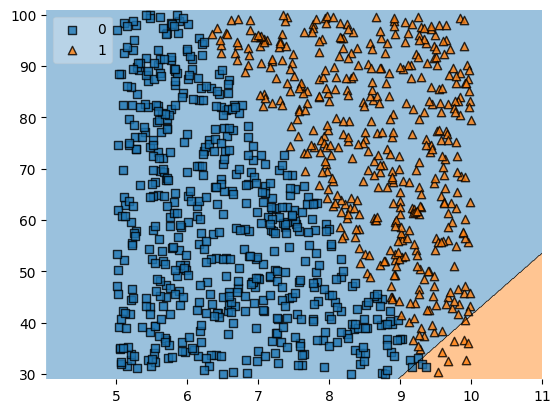

In [10]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X.values, y.values, clf=p, legend=2)

In [11]:
X = df.iloc[:, 0:2].copy()
X.insert(0, 'bias', 1)

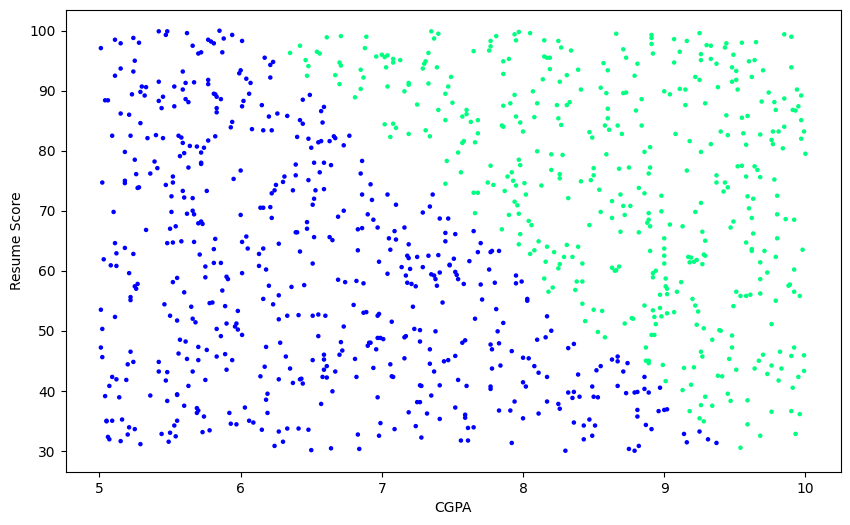

In [12]:
plt.figure(figsize=(10,6))
plt.scatter(X.iloc[:, 1], X.iloc[:, 2], c=y, cmap='winter', s=5)
plt.xlabel('CGPA')
plt.ylabel('Resume Score')
plt.show()

In [13]:
def step(z):
    return 1 if z >= 0 else 0

In [14]:
def perceptrone(X, y):
    X = X.to_numpy()
    W = np.ones(X.shape[1])
    lr = 0.1

    for i in range(100000):
        j = np.random.randint(0, X.shape[0])
        y_hat = step(X[j] @ W)
        W = W + lr * (y[j] - y_hat) * X[j]

    return W[0], W[1:]

In [15]:
b, w = perceptrone(X, y)

In [16]:
print(b)
print(w)

-256.09999999998973
[23.309  1.16 ]


In [17]:
x1 = np.linspace(X.iloc[:, 1].min(), X.iloc[:, 1].max(), 1000)
x2 = -(x1 * w[0] + b) / w[1]

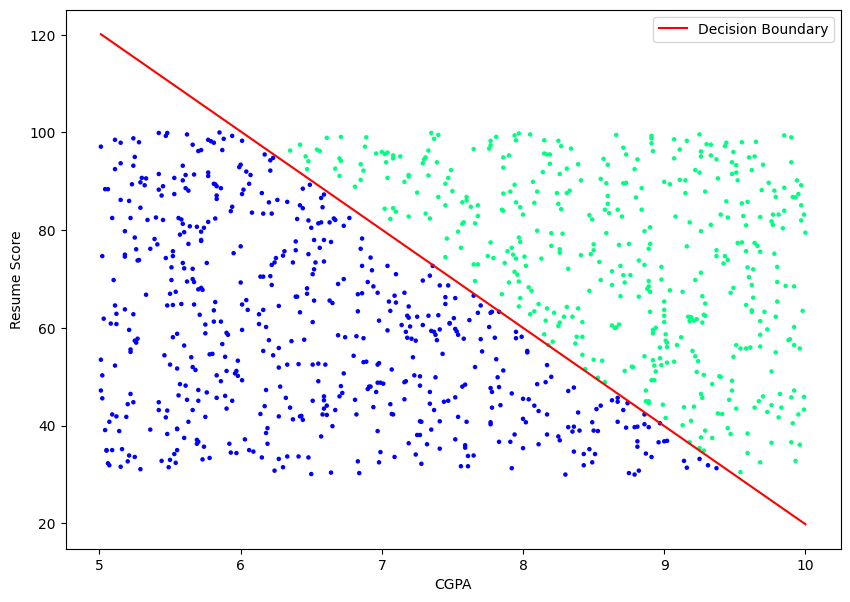

In [18]:
plt.figure(figsize=(10,7))
plt.plot(x1, x2, color='red', label='Decision Boundary')
plt.scatter(X.iloc[:,1], X.iloc[:,2], c=y, cmap='winter', s=5)

plt.xlabel('CGPA')
plt.ylabel('Resume Score')
plt.legend()
plt.show()

In [19]:
def perceptrone(X, y):
    w1 = w2 = b = 1
    lr = 0.1

    for j in range(1500):
        for i in range(X.shape[0]):
            z = w1*X[i][1] + w2*X[i][2] + b

            if z * y[i] < 0:
                w1 = w1 + lr*y[i]*X[i][1]
                w2 = w2 + lr*y[i]*X[i][2]
                b = b + lr * y[i]

    return w1, w2, b

In [20]:
w1, w2, b = perceptrone(X.to_numpy(), np.where(np.asarray(y) == 0, -1, 1))

In [21]:
x1 = np.linspace(X.iloc[:, 1].min(), X.iloc[:, 1].max(), 1000)
x2 = -(x1 * w1 + b) / w2

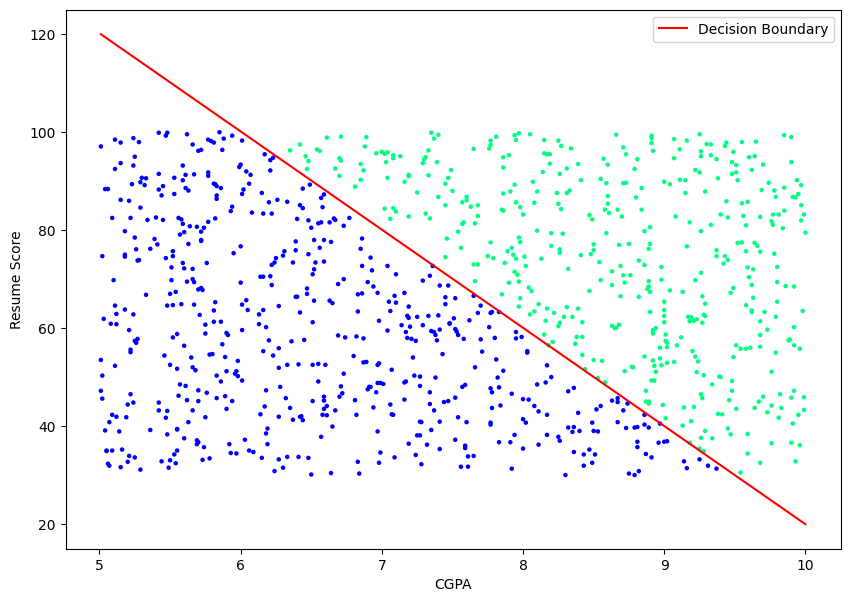

In [22]:
plt.figure(figsize=(10,7))
plt.plot(x1, x2, color='red', label='Decision Boundary')
plt.scatter(X.iloc[:,1], X.iloc[:,2], c=y, cmap='winter', s=5)

plt.xlabel('CGPA')
plt.ylabel('Resume Score')
plt.legend()
plt.show()